In [2]:
import numpy as np
from data_l63_v1 import create_and_save_dataset
from scipy.integrate import solve_ivp
from scipy.stats import qmc, multivariate_normal
import matplotlib.pyplot as plt

In [3]:
# ---------------------------
T_window = 1
dt_subsample = 1
# Create dataset
create_and_save_dataset(f"./data/l63_sobol_dt{dt_subsample}_T{T_window}.npz", 
                        prior_type="sobol", N_params=256, N_traj_per_param=200, dt_subsample=dt_subsample, T_window=T_window)


Dataset saved to ./data/l63_sobol_dt1_T1.npz


In [15]:
mus = [
    [10, 28, 8/3],   # Mode 1
    [15, 35, 3.5]    # Mode 2
]
covs = [
    np.diag([2**2, 4**2, 0.3**2]),
    np.diag([1**2, 3**2, 0.2**2])
]
weights = [0.1, 0.9]
dt_subsample = 2
T_window = 20
create_and_save_dataset(
    f"./data/l63_GMM_dt{dt_subsample}_T{T_window}_w19.npz",
    prior_type="mixture_gaussian",
    mus=mus,
    covs=covs,
    weights=weights,
    N_params=256, N_traj_per_param=200,
    dt_subsample = 1,
    T_window = 1
)

Dataset saved to ./data/l63_GMM_dt2_T20_w19.npz


In [47]:
# --- latent GMM that maps to (sigma, rho, beta) ---
# Mode 1 targets ~ (sigma=10, rho=28, beta=8/3)
# Mode 2 targets ~ (sigma=15, rho=35, beta=3.5)
mus_L = [
    [8.0, 20.0, 10.0, 8/3, 0.0],   # theta1, theta2, theta3, theta4, theta5
    [19.5, 15.5, 15.0, 3.5, 0.0],
]
covs_L = [
    np.diag([2.0**2, 2.0**2, 1.0**2, 0.3**2, 1.0**2]),
    np.diag([1.0**2, 1.0**2, 0.7**2, 0.2**2, 1.0**2]),
]
weights_L = [0.2, 0.8]

dt_subsample = 2
T_window = 20

create_and_save_dataset(
    save_path=f"./data/l63_LATENT_GMM_dt{dt_subsample}_T{T_window}_w28_v2.npz",
    prior_type="latent_mixture_gaussian",
    mus_L=mus_L,
    covs_L=covs_L,
    weights_L=weights_L,
    N_params=256,
    N_traj_per_param=200,
    dt_subsample=dt_subsample,
    T_window=T_window,
    clip_physical=False,   # keep true prior geometry in mapped (sigma,rho,beta)
         # also saves latent_train / latent_test
)


Dataset saved to ./data/l63_LATENT_GMM_dt2_T20_w28_v2.npz


In [9]:

recommended_combinations = [
    # # Anchor points (known performance)
    # (1, 1),    # poor - 2 points
    # (20, 2),   # good - 11 points
    
    # Test trajectory length effect (fixed ~6 points)
    (5, 1),    # short, dense - 6 points
    (10, 2),   # medium, medium - 6 points
    (20, 4),   # long, sparse - 6 points
    
    # Test sampling frequency effect (fixed T=10)
    (10, 1),   # dense - 11 points
    (10, 2),   # medium - 6 points
    (10, 5),   # sparse - 3 points
    
    # Additional key points
    (2, 1),    # very short - 3 points
    (5, 2),    # 4 points
    (20, 1),   # dense long - 21 points
    (30, 2),   # very long - 16 points
]

# ============ CODE IMPLEMENTATION ============
t_window_list = [combo[0] for combo in recommended_combinations]
dt_subsample_list = [combo[1] for combo in recommended_combinations]

# Or if you want to use them as tuples:
combinations = recommended_combinations

In [10]:
mus = [
    [10, 28, 8/3],   # Mode 1
    [15, 35, 3.5]    # Mode 2
]
covs = [
    np.diag([2**2, 4**2, 0.3**2]),
    np.diag([1**2, 3**2, 0.2**2])
]
weights = [0.2, 0.8]
dt_subsample = 2
T_window = 20

for T_window, dt_subsample in recommended_combinations:
    print (f"dt{dt_subsample}_T{T_window}")
    create_and_save_dataset(
        f"./data/l63_GMM_dt{dt_subsample}_T{T_window}_w28.npz",
        prior_type="mixture_gaussian",
        mus=mus,
        covs=covs,
        weights=weights,
        N_params=256, N_traj_per_param=10,
        dt_subsample = dt_subsample,
        T_window = T_window
    )

dt1_T5
Dataset saved to ./data/l63_GMM_dt1_T5_w28.npz
dt2_T10
Dataset saved to ./data/l63_GMM_dt2_T10_w28.npz
dt4_T20
Dataset saved to ./data/l63_GMM_dt4_T20_w28.npz
dt1_T10
Dataset saved to ./data/l63_GMM_dt1_T10_w28.npz
dt2_T10
Dataset saved to ./data/l63_GMM_dt2_T10_w28.npz
dt5_T10
Dataset saved to ./data/l63_GMM_dt5_T10_w28.npz
dt1_T2
Dataset saved to ./data/l63_GMM_dt1_T2_w28.npz
dt2_T5
Dataset saved to ./data/l63_GMM_dt2_T5_w28.npz
dt1_T20
Dataset saved to ./data/l63_GMM_dt1_T20_w28.npz
dt2_T30
Dataset saved to ./data/l63_GMM_dt2_T30_w28.npz


In [9]:
import numpy as np
from scipy.stats import multivariate_normal

def sample_parameters_mixture(N, mus, covs, weights, ranges):
    """
    Sample from a mixture of Gaussians.
    
    Parameters:
        N: int, number of samples
        mus: list of mean vectors (one per mode)
        covs: list of covariance matrices (one per mode)
        weights: list of mixture weights (sum to 1)
        ranges: list of (min, max) tuples for clipping each parameter
    """
    mus = np.array(mus)
    covs = np.array(covs)
    weights = np.array(weights) / np.sum(weights)  # normalize
    
    # Decide which Gaussian each sample will come from
    components = np.random.choice(len(weights), size=N, p=weights)
    
    samples = np.zeros((N, mus.shape[1]))
    
    for i, comp in enumerate(components):
        samples[i] = multivariate_normal(mean=mus[comp], cov=covs[comp]).rvs()
    
    # Clip to provided parameter ranges
    for dim, (low, high) in enumerate(ranges):
        samples[:, dim] = np.clip(samples[:, dim], low, high)
    
    return samples


In [2]:

recommended_combinations = [
    # Anchor points (known performance)
    (1, 1),    # poor - 2 points
    (20, 2),   # good - 11 points
    
    # Test trajectory length effect (fixed ~6 points)
    (5, 1),    # short, dense - 6 points
    (10, 2),   # medium, medium - 6 points
    (20, 4),   # long, sparse - 6 points
    
    # Test sampling frequency effect (fixed T=10)
    (10, 1),   # dense - 11 points
    (10, 2),   # medium - 6 points
    (10, 5),   # sparse - 3 points
    
    # Additional key points
    (2, 1),    # very short - 3 points
    (5, 2),    # 4 points
    (20, 1),   # dense long - 21 points
    (30, 2),   # very long - 16 points
]

# ============ CODE IMPLEMENTATION ============
t_window_list = [combo[0] for combo in recommended_combinations]
dt_subsample_list = [combo[1] for combo in recommended_combinations]

# Or if you want to use them as tuples:
combinations = recommended_combinations

In [5]:
for dt, T in recommended_combinations:
    print (dt, T)

1 1
20 2
5 1
10 2
20 4
10 1
10 2
10 5
2 1
5 2
20 1
30 2


In [ ]:
import numpy as np

# ---------- EASY: well-separated modes, small overlap ----------
# Target rhos near classic L63 but separated:
#   Mode A:  ρ ≈ 24  (θ1+θ2 = 48)
#   Mode B:  ρ ≈ 32  (θ1+θ2 = 64)
mus_L_easy = [
    [26.0, 22.0, 10.0, 8/3, 0.0],   # [θ1, θ2, θ3(=σ), θ4(=β), θ5(dummy)]
    [34.0, 30.0, 15.0, 3.5, 0.0],
]
covs_L_easy = [
    np.diag([1.5**2, 1.5**2, 1.0**2, 0.3**2, 1.0**2]),
    np.diag([1.5**2, 1.5**2, 1.0**2, 0.3**2, 1.0**2]),
]
weights_L_easy = [0.2, 0.8]

# ---------- INTERMEDIATE: some overlap, larger std on θ1,θ2 ----------
# Closer means + bigger stds:
#   Mode A:  ρ ≈ 26  (θ1+θ2 = 52)
#   Mode B:  ρ ≈ 30  (θ1+θ2 = 60)
mus_L_inter = [
    [28.0, 24.0, 10.5, 3.2, 0.0],   # ρ ≈ 26
    [31.0, 29.0, 14.5, 3.3, 0.0],   # ρ ≈ 30
]
covs_L_inter = [
    np.diag([3.5**2, 3.5**2, 1.2**2, 0.35**2, 1.0**2]),
    np.diag([3.5**2, 3.5**2, 1.2**2, 0.35**2, 1.0**2]),
]
weights_L_inter = [0.2, 0.8]


# ---------- HARD: mirror modes with identical sum (exchangeable) ----------
# Both modes have (theta1+theta2/2) = 30 (e.g., 22+8 and 8+22), same σ and β.
# Large std on θ1,θ2 makes it hard to tell θ1 vs θ2; diagonal only (no corr).
mus_L_hard = [
    [40.0,  16.0, 12.0, 3.2, 0.0],   # rho = 30 (or 15 if you halve later)
    [ 16.0, 40.0, 12.0, 3.2, 0.0],
]
covs_L_hard = [
    np.diag([5.0**2, 5.0**2, 1.0**2, 0.3**2, 1.0**2]),
    np.diag([5.0**2, 5.0**2, 1.0**2, 0.3**2, 1.0**2]),
]
weights_L_hard = [0.2, 0.8]

# ---------- choose a case and generate ----------
dt_subsample = 1
T_window = 200

# EXAMPLE: use the HARD case (swap to *_easy or *_inter as needed)
mus_L   = mus_L_hard
covs_L  = covs_L_hard
weights_L = weights_L_hard

all_cases = {"easy": (mus_L_easy, covs_L_easy, weights_L_easy),
            "intermediate": (mus_L_inter, covs_L_inter, weights_L_inter),
            "hard": (mus_L_hard, covs_L_hard, weights_L_hard)}
for case, (mus_L, covs_L, weights_L) in all_cases.items():
    print (f"Generating case: {case}")
    create_and_save_dataset(
        save_path=f"./data/l63_LATENT_GMM_dt{dt_subsample}_T{T_window}_w28_{case}.npz",
        prior_type="latent_mixture_gaussian",
        mus_L=mus_L,
        covs_L=covs_L,
        weights_L=weights_L,
        N_params=256,
        N_traj_per_param=200,
        dt_subsample=dt_subsample,
        T_window=T_window,
        avg = True,
        clip_physical=False,   # keep true latent geometry -> mapped (σ,ρ,β)
        save_physical=False
)


Generating case: hard
Dataset saved to ./data/l63_LATENT_GMM_dt5_T50_w28_hard.npz


In [49]:
# import xarray as xr
ds= np.load("./data/l63_LATENT_GMM_dt2_T20_intermediate.npz")

In [50]:
params_train = ds["theta_train"]   # (N_train, 3) -> [sigma, rho, beta]
trajs_train  = ds["trajs_train"] 

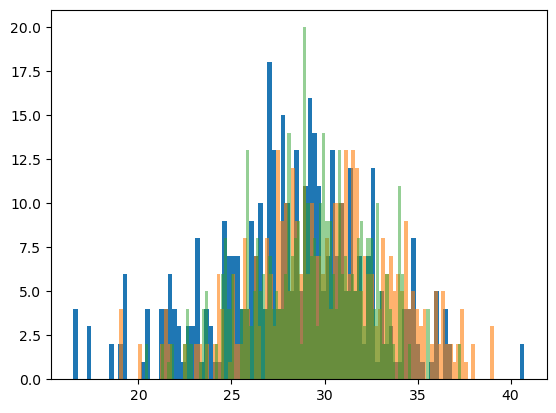

In [51]:
_ = plt.hist(params_train[:,1] ,bins = 100,alpha = 1)
_ = plt.hist(params_train[:,0] ,bins = 100,alpha = 0.6)
_ = plt.hist((params_train[:,0] + params_train[:,1])/2,bins = 100,alpha = 0.5)


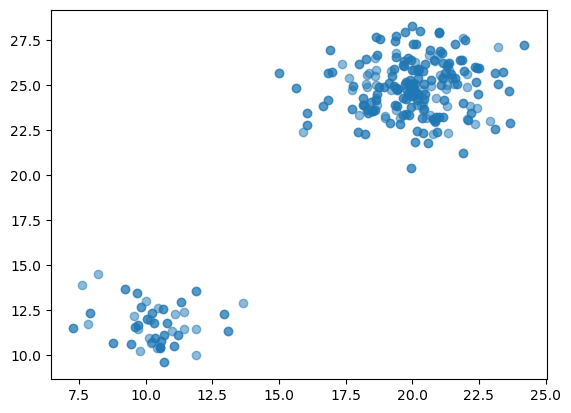

In [28]:
plt.scatter(params_train[:,1], params_train[:,0], alpha=0.5)
# plt.scatter(params_train[:,1] + params_train[:,:], params_train[:,0], alpha=0.5)
